In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import uproot
import matplotlib

In [2]:
def applyCut(inputDataframe, cut, text=None):
    dataframe = inputDataframe
    nbeforecut = dataframe.shape[0]
    cutDataframe = dataframe.query(cut)
    if text:
        print (text, cutDataframe.shape[0], ' fraction kept: %2.1f'%(100.0*float(cutDataframe.shape[0])/nbeforecut))
    return cutDataframe

def getData(observables, filename, treename):
    return (uproot.open(filename)[treename]).arrays(observables, library='pd')

def getRcAndErr(df, ob):
    if (ob == 'b'):
        nos = sum(df[df.b==-1]['w'])
        nss = sum(df[df.b==+1]['w'])
    elif (ob == 'b_ch'):
        nos = sum(df[df.b_ch==-1]['w'])
        nss = sum(df[df.b_ch==+1]['w'])
    elif (ob == 'bs'):
        nos = sum(df[df.bs==-1]['ws'])
        nss = sum(df[df.bs==+1]['ws'])
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    w_array = np.unique(df['w'])
    err2_array = []
    variance_array_test = []
    for i in range(0, len(w_array)):
        if (ob == 'b'):
            p = sum(df[(df.w == w_array[i]) & (df.b==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])
        elif (ob == 'b_ch'):
            p = sum(df[(df.w == w_array[i]) & (df.b_ch==+1)]['w']) / sum(df[df.w == w_array[i]]['w'])            
        elif (ob == 'bs'):
            p = sum(df[(df.w == w_array[i]) & (df.bs==+1)]['w']) / sum(df[df.w == w_array[i]]['ws'])
        else:
            print('Double check the input observable name!')        
        variance = p*(1-p)/df[df.w == w_array[i]].shape[0]
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2_array.append ( w**2*variance )
    rc_err = 2*np.sqrt(sum(err2_array))
    return rc, rc_err

def calc_hist_nonuniform(vals, bins, weights, density=False):
    if weights is None:
        weights = np.ones(vals.shape)    
    hist, bins = np.histogram(vals, bins=bins, weights=weights)    
    digits = np.digitize(vals, bins)
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])
    for i in range(1, len(bins)):
        hist[i-1] /= (bins[i] - bins[i-1])
        errs[i-1] /= (bins[i] - bins[i-1])
    if density:
        hist /= weights.sum()
        errs /= weights.sum()
    return hist, errs, bins

In [49]:
def calc_hist(vals, bins=10, weights=None, density=False):    
    if weights is None:
        weights = np.ones(vals.shape)
    hist, bins = np.histogram(vals, bins=bins, weights=weights)
    digits = np.digitize(vals, bins)
    errs = np.asarray([np.linalg.norm(weights[digits==i]) for i in range(1, len(bins))])
    if density:
        density_int = weights.sum() * (bins[1] - bins[0])
        hist /= density_int
        errs /= density_int
    return hist, errs, bins

In [3]:
observables1 = ['pt','b','w','y1','y2','phi1','phi2']
observabless1 = ['pts','bs','ws','y1s','y2s','phi1s','phi2s','nefs']
df_allreco = applyCut(getData(observables1+observabless1, '/vast/palmer/home.grace/ys668/output/run12/all050124_rc.root', "MatchedTree"),\
              'pts>15 and bs!=-9 and w<1')

In [3]:
df_allreco = applyCut(pd.read_csv('/vast/palmer/home.grace/ys668/output/run12/all050124_rc_notrueptcons.csv', low_memory=False),\
                      'pts>15 and bs!=-9 and w<1')

In [47]:
observables2 = ['pt','b','nef']
file = uproot.open('/gpfs/gibbs/project/havener/ys668/rc/data0613_chargedrc.root')
tree = file["ResultTree"].arrays(observables2, library='np')
df_data = pd.DataFrame(np.transpose(np.array((np.concatenate(tree['pt']),np.concatenate(tree['b']), np.concatenate(tree['nef'])))), columns=["pts","bs","nefs"])
df_data = applyCut(df_data, 'pts>15 and bs!=-9')

# Reweight to match the pT spectrum in data

In [5]:
binedges_array = [np.array([15, 20, 25, 30, 40, 60])]
ob_array = ['pts']
ob_label_array = ['$p_{\mathrm{T}}$ [GeV$/c$]']


observable: pts , binedges: [15 20 25 30 40 60]
MC effective counts: [125469.1407362168, 175356.8672716962, 94297.44271330138, 60334.948093672436, 12862.549670944014]
Data rel. stat. unc.: [0.00139285 0.00300241 0.00630717 0.01167934 0.04531433]
chi2: 386.94732409983254 chi2 pull: 120.78234903619921
y_data/y_prior:  [0.98773829 1.03816619 1.0772542  1.06624948 1.14991864]


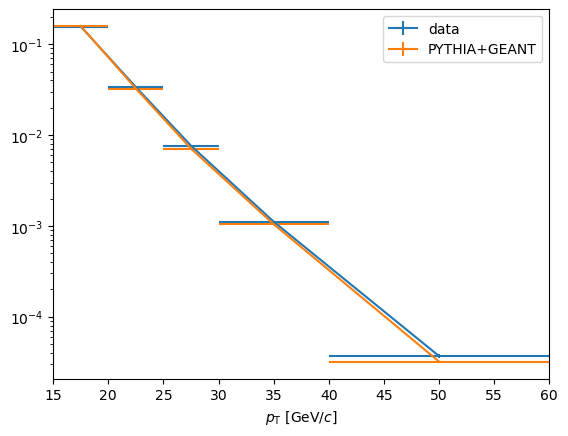

In [6]:
for i in range(0, len(ob_array)):
    ob = ob_array[i]
    binedges = binedges_array[i]

    print('\nobservable:', ob, ', binedges:', binedges)
    x = []
    neff_array = []
    for j in range(0, len(binedges)-1):
        midpoint = 0.5 * (binedges[j] + binedges[j+1])
        x.append(midpoint)
        neff = sum(df_allreco[(df_allreco[ob]>binedges[j]) & (df_allreco[ob]<binedges[j+1])]['w'])**2 / (1e-50+sum(df_allreco[(df_allreco[ob]>binedges[j]) & (df_allreco[ob]<binedges[j+1])]['w']**2))
        neff_array.append(neff)
    print("MC effective counts:", neff_array)
    y_data, err_data = calc_hist_nonuniform(df_data[ob], bins=binedges, weights=np.ones(df_data.shape[0]), density=True)[:2]
    y_prior, err_prior = calc_hist_nonuniform(df_allreco[ob], bins=binedges, weights=df_allreco['w'], density=True)[:2]
    print("Data rel. stat. unc.:", err_data/y_data)
        
    chi2 = 0
    for j in range(0, len(binedges)-2):
        chi2 += ((y_prior[j]-y_data[j])**2) / (err_data[j]**2)
    dof = len(binedges) - 1
    z_chi2 = (chi2-dof)/np.sqrt(2*dof)
    print("chi2:", chi2, "chi2 pull:", z_chi2)
    
    plt.cla()
    plt.errorbar(x, y_data, xerr=binedges[1:]-x,  yerr=err_data, label='data')
    plt.errorbar(x, y_prior, xerr=binedges[1:]-x, yerr=err_prior, label='PYTHIA+GEANT')
    print('y_data/y_prior: ', y_data/y_prior)
    plt.xlabel(ob_label_array[i])
    plt.xlim(binedges[0], binedges[-1])
    plt.yscale('log')
    plt.legend()
    plt.show()

In [7]:
print('y_data/y_prior: ', y_data/y_prior)
y_ratio = y_data/y_prior

y_data/y_prior:  [0.98773829 1.03816619 1.0772542  1.06624948 1.14991864]


In [8]:
df_allreco['y_ratio'] = np.ones(df_allreco.shape[0])
for j in range(0, len(binedges)-1):
    df_allreco.loc[(df_allreco[ob]<binedges[j+1])&(df_allreco[ob]>binedges[j]), 'y_ratio'] = y_ratio[j]
df_allreco.eval('rw=w*y_ratio', inplace=True)

In [9]:
df_allreco['w'] = df_allreco['rw']
df_allreco['ws'] = df_allreco['rw']

In [10]:
distance1 = []
distance2 = []
for i in range(0,df_allreco.shape[0]):
    phi1small = min(df_allreco.iloc[i]['phi1'], df_allreco.iloc[i]['phi1s'])
    phi1large = max(df_allreco.iloc[i]['phi1'], df_allreco.iloc[i]['phi1s'])
    phi2small = min(df_allreco.iloc[i]['phi2'], df_allreco.iloc[i]['phi2s'])
    phi2large = max(df_allreco.iloc[i]['phi2'], df_allreco.iloc[i]['phi2s'])
    dphi1 = min(phi1large-phi1small, 6.283185307179586-(phi1large-phi1small))
    dphi2 = min(phi2large-phi2small, 6.283185307179586-(phi2large-phi2small))
    if (dphi1 > np.pi):
        print(df_allreco.iloc[i]['phi1'], df_allreco.iloc[i]['phi1s'], dphi1)
    distance1.append(np.sqrt(dphi1**2+(df_allreco.iloc[i]['y1']-df_allreco.iloc[i]['y1s'])**2))
    distance2.append(np.sqrt(dphi2**2+(df_allreco.iloc[i]['y2']-df_allreco.iloc[i]['y2s'])**2))
df_allreco['distance1'] = distance1
df_allreco['distance2'] = distance2

In [11]:
df_allreco.to_csv('/vast/palmer/home.grace/ys668/output/run12/all050124_reco_rw_notrueptcons.csv', index=False)

Process PYTHIA6+GEANT

In [12]:
df_match = applyCut(df_allreco, 'pt!=-9 and b!=-9 and distance1<0.02 and distance2<0.02')
df_allfake = applyCut(df_allreco, 'pt==-9 or b==-9 or distance1>0.02 or distance2>0.02')

In [13]:
print(df_match.shape[0], df_allfake.shape[0])

2630097 1465062


In [14]:
print(np.unique(df_match['bs']))

[-1  1]


In [15]:
df_allreco_pts_array = [ df_allreco[(df_allreco.pts>15) & (df_allreco.pts<20)],\
                       df_allreco[(df_allreco.pts>20) & (df_allreco.pts<25)],\
                       df_allreco[(df_allreco.pts>25) & (df_allreco.pts<30)],\
                       df_allreco[(df_allreco.pts>30) & (df_allreco.pts<40)],\
                       df_allreco[(df_allreco.pts>40) & (df_allreco.pts<60)]]

df_match_pts_array = [ df_match[(df_match.pts>15) & (df_match.pts<20)],\
                       df_match[(df_match.pts>20) & (df_match.pts<25)],\
                       df_match[(df_match.pts>25) & (df_match.pts<30)],\
                       df_match[(df_match.pts>30) & (df_match.pts<40)],\
                       df_match[(df_match.pts>40) & (df_match.pts<60)] ]

df_allfake_pts_array = [ df_allfake[(df_allfake.pts>15) & (df_allfake.pts<20)],\
                       df_allfake[(df_allfake.pts>20) & (df_allfake.pts<25)],\
                       df_allfake[(df_allfake.pts>25) & (df_allfake.pts<30)],\
                       df_allfake[(df_allfake.pts>30) & (df_allfake.pts<40)],\
                       df_allfake[(df_allfake.pts>40) & (df_allfake.pts<60)]  ]

In [16]:
rc_allreco_bs_vs_pts_array = []
rc_err_allreco_bs_vs_pts_array = []
for i in range(0, len(df_allreco_pts_array)):
    rc_allreco_bs_vs_pts_array.append(getRcAndErr(df_allreco_pts_array[i], 'bs')[0])
    rc_err_allreco_bs_vs_pts_array.append(getRcAndErr(df_allreco_pts_array[i], 'bs')[1])
    
rc_match_bs_vs_pts_array = []
rc_err_match_bs_vs_pts_array = []
for i in range(0, len(df_match_pts_array)):
    rc_match_bs_vs_pts_array.append(getRcAndErr(df_match_pts_array[i], 'bs')[0])
    rc_err_match_bs_vs_pts_array.append(getRcAndErr(df_match_pts_array[i], 'bs')[1])

rc_allfake_bs_vs_pts_array = []
rc_err_allfake_bs_vs_pts_array = []
for i in range(0, len(df_allfake_pts_array)):
    rc_allfake_bs_vs_pts_array.append(getRcAndErr(df_allfake_pts_array[i], 'bs')[0])
    rc_err_allfake_bs_vs_pts_array.append(getRcAndErr(df_allfake_pts_array[i], 'bs')[1])

In [17]:
plt.rcParams['font.size'] = 12

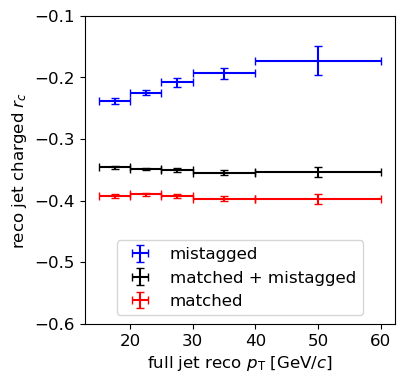

In [18]:
fig=plt.figure(figsize=(4,4))
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_allfake_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_allfake_bs_vs_pts_array, capsize=3, color='b', ls='none', label='mistagged')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_allreco_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_allreco_bs_vs_pts_array, capsize=3, color='k', ls='none', label='matched + mistagged')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_match_bs_vs_pts_array, capsize=3, color='r', ls='none', label='matched')
plt.xlabel('full jet reco $p_{\mathrm{T}}$ [GeV$/c$]')
plt.ylabel('reco jet charged $r_c$')
plt.ylim(-0.6,-0.1)
plt.legend(loc='lower center')

In [19]:
rc_allfake_bs_vs_pts_array

[-0.2381034581515094,
 -0.22484574982877792,
 -0.2081112905981685,
 -0.19305953641181442,
 -0.1727017686454173]

In [20]:
ob = 'b'
range_low = -1.2
range_high = 1.2
bins = 2

In [22]:
b_fake_array = []
for i in range(0,5):
    df_fake_pts = df_allfake_pts_array[i]
    y_fake_rec,yerr_fake_rec,x = calc_hist_nonuniform(df_fake_pts[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_fake_pts['ws'], density=True)
    b_fake_array.append(y_fake_rec/sum(y_fake_rec))

In [23]:
b_fake_array

[array([0.61905173, 0.38094827]),
 array([0.61242287, 0.38757713]),
 array([0.60405565, 0.39594435]),
 array([0.59652977, 0.40347023]),
 array([0.58635088, 0.41364912])]

In [24]:
df_match_pt_array = [ df_match[(df_match.pt>15) & (df_match.pt<20)],\
                       df_match[(df_match.pt>20) & (df_match.pt<25)],\
                       df_match[(df_match.pt>25) & (df_match.pt<30)],\
                       df_match[(df_match.pt>30) & (df_match.pt<40)],\
                       df_match[(df_match.pt>40) & (df_match.pt<60)]  ]

In [25]:
rc_match_bs_vs_pt_array = []
rc_err_match_bs_vs_pt_array = []
for i in range(0, len(df_match_pt_array)):
    rc_match_bs_vs_pt_array.append(getRcAndErr(df_match_pt_array[i], 'bs')[0])
    rc_err_match_bs_vs_pt_array.append(getRcAndErr(df_match_pt_array[i], 'bs')[1])

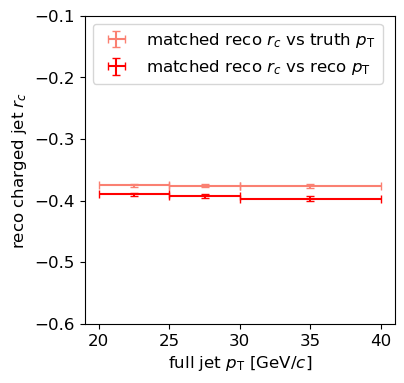

In [26]:
fig=plt.figure(figsize=(4,4))
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pt_array[1:-1], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pt_array[1:-1], capsize=3, color='salmon', ls='none', label='matched reco $r_c$ vs truth $p_{\mathrm{T}}$')
plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pts_array[1:-1], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pts_array[1:-1], capsize=3, color='r', ls='none', label='matched reco $r_c$ vs reco $p_{\mathrm{T}}$')
plt.xlabel('full jet $p_{\mathrm{T}}$ [GeV$/c$]')
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('reco charged jet $r_c$')
plt.ylim(-0.6,-0.1)
plt.legend(loc='upper left')

In [28]:
b_match_array = []
for i in range(0,5):
    df_match_pts = df_match_pts_array[i]
    y_reco,yerr_reco,x = calc_hist_nonuniform(df_match_pts[ob+'s'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins), weights=df_match_pts['ws'], density=True)
    b_match_array.append(y_reco/sum(y_reco))
    print(y_reco/sum(y_reco))

[0.69613892 0.30386108]
[0.69480392 0.30519608]
[0.69601395 0.30398605]
[0.69861309 0.30138691]
[0.69865203 0.30134797]


In [29]:
binedges=[5,10,15,20,25,30,40,60]
match_fake, x = np.histogram(df_allreco['pts'], bins=binedges, weights=df_allreco['ws'])
match, _ = np.histogram(df_allreco[(df_allreco.pt!=-9) & (df_allreco.b!=-9) & (df_allreco.distance1<0.02) & (df_allreco.distance2<0.02)]['pts'], bins=binedges, weights=df_allreco[(df_allreco.pt!=-9) & (df_allreco.b!=-9) & (df_allreco.distance1<0.02) & (df_allreco.distance2<0.02)]['ws'])
eff4 = match/match_fake

/tmp/ipykernel_3118471/4101531506.py:4: RuntimeWarning: invalid value encountered in divide
  eff4 = match/match_fake


In [30]:
fake_rate_array = np.ones(5)-eff4[2:7]
fake_rate_array

array([0.29936725, 0.24871326, 0.22291703, 0.2064793 , 0.19306711])

Process data

In [31]:
df_data_pts_array = [ df_data[(df_data.pts>15) & (df_data.pts<20)],\
                       df_data[(df_data.pts>20) & (df_data.pts<25)],\
                       df_data[(df_data.pts>25) & (df_data.pts<30)],\
                       df_data[(df_data.pts>30) & (df_data.pts<40)],\
                       df_data[(df_data.pts>40) & (df_data.pts<60)]  ]

In [32]:
def getRcAndErrAndN(df, ob):
    if (ob == 'bs'):
        nos = df[df.bs==-1].shape[0]
        nss = df[df.bs==+1].shape[0]
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    n = nss+nos
    rc_err = 2*np.sqrt(p*(1-p)/n)
    return rc, rc_err, n

In [33]:
rc_data_bs_vs_pts_array = []
rc_err_data_bs_vs_pts_array = []
for i in range(0, len(df_data_pts_array)):
    rc_data_bs_vs_pts_array.append(getRcAndErrAndN(df_data_pts_array[i], 'bs')[0])
    rc_err_data_bs_vs_pts_array.append(getRcAndErrAndN(df_data_pts_array[i], 'bs')[1])

In [50]:
b_data_array = []
for i in range(0,5):
    df_data_pts = df_data_pts_array[i]
    y_reco,yerr_reco,x = calc_hist(df_data_pts['bs'], bins=np.arange(range_low,range_high+(range_high-range_low)/bins, (range_high-range_low)/bins))
    b_data_array.append(y_reco)

In [51]:
print(b_data_array)

[array([337314., 178144.]), array([72379., 38554.]), array([16450.,  8688.]), array([4758., 2573.]), array([334., 153.])]


# 1. Mistagged subtraction

In [52]:
def getMatchedCountAndErr(data, fake_rate, fake_dist):
    corrected = data - sum(data) * fake_rate * fake_dist
    err = np.sqrt(corrected)
    return corrected, err

In [53]:
b_fakesubtracted_array = []
b_fakesubtractederr_array = []
rc1_array = []
rc1_err_array = []
for i in range(0,5):
    print(i)
    print(b_data_array[i])
    #print(getRc(data_array[i]))
    b_fakesubtracted, b_fakesubtractederr = getMatchedCountAndErr(b_data_array[i], fake_rate_array[i], b_fake_array[i])
    b_fakesubtracted_array.append(b_fakesubtracted)
    b_fakesubtractederr_array.append(b_fakesubtractederr)
    print(b_fakesubtracted)
    print(b_fakesubtractederr)
    nos = b_fakesubtracted[0]
    nss = b_fakesubtracted[1]
    n = nos + nss
    p = nss / n
    rc1 = (nss-nos) / (nss+nos)
    rc1_array.append(rc1)
    rc1_err_array.append( 2*np.sqrt(p*(1-p)/n) )

0
[337314. 178144.]
[241787.35901385 119359.39929276]
[491.71878042 345.48429674]
1
[72379. 38554.]
[55481.94187548 27860.55029639]
[235.54605043 166.91479951]
2
[16450.  8688.]
[13065.06044942  6469.25125311]
[114.30249538  80.43165579]
3
[4758. 2573.]
[3855.03301837 1962.26719705]
[62.0889122  44.29748522]
4
[334. 153.]
[278.86912984 114.10718633]
[16.69937513 10.68209653]


In [54]:
print(rc_data_bs_vs_pts_array)

[-0.3087933449476, -0.3049137767841851, -0.30877555891479036, -0.2980493793479744, -0.37166324435318276]


Text(20, -0.2, '$p$+$p$ $\\sqrt{s}=200$ GeV\nanti-$k_{\\mathrm{T}}$ jets, $R=0.4$')

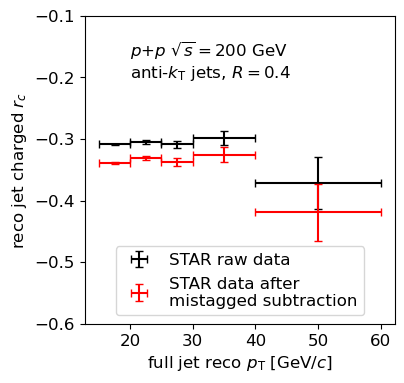

In [55]:
fig=plt.figure(figsize=(4,4))
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_data_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_data_bs_vs_pts_array, capsize=3, color='k', ls='none', label='STAR raw data')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc1_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc1_err_array, capsize=3, color='r', ls='none', label='STAR data after\nmistagged subtraction')
plt.xlabel('full jet reco $p_{\mathrm{T}}$ [GeV$/c$]')
plt.ylabel('reco jet charged $r_c$')
plt.ylim(-0.6,-0.1)
plt.legend(loc='lower center')
plt.text(20, -0.2, '$p$+$p$ $\sqrt{s}=200$ GeV\nanti-$k_{\mathrm{T}}$ jets, $R=0.4$')

# 2. $p_T$ correction

In [56]:
reweight_array = []
for i in range(0,5):
    reweight = (b_fakesubtracted_array[i]/sum(b_fakesubtracted_array[i]))/(b_match_array[i]/sum(b_match_array[i]))
    reweight_array.append(reweight)

In [57]:
reweight_array

[array([0.96173176, 1.08767168]),
 array([0.95812662, 1.09532818]),
 array([0.960938  , 1.08943732]),
 array([0.94857114, 1.11921181]),
 array([1.01571797, 0.96355909])]

([], [])

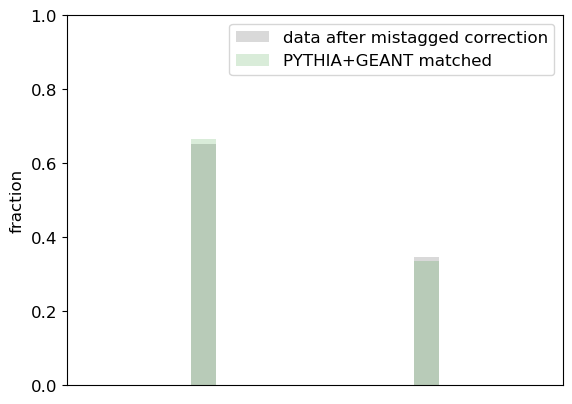

In [58]:
x = np.array([-0.5, 0.5])
plt.hist(x, weights=b_data_array[1]/sum(b_data_array[1]), color='k', alpha=0.15, label='data after mistagged correction')
plt.hist(x, weights=b_fakesubtracted_array[1]/sum(b_fakesubtracted_array[1]), ls='none', color='g', alpha=0.15, label='PYTHIA+GEANT matched')
#plt.errorbar(x+np.array([0.05,-0.05]), b_data_array[1][0]/sum(b_data_array[1]), yerr=y1err_array[0]/sum(b_data_array[1]), capsize=3, color='k', ls='none')
#plt.errorbar(x+np.array([0.05,-0.05]), b_fakesubtracted_array[1][0]/sum(b_fakesubtracted_array[1]), yerr=y1err_pythia_array[0]/sum(b_fakesubtracted_array[1]), capsize=3, color='g', ls='none')
plt.legend(fontsize=12)
plt.ylabel('fraction')
plt.xlim(range_low,range_high)
plt.ylim(bottom=0)
plt.xlim(-1,1)
plt.ylim(0,1)
plt.xlabel('')
plt.xticks([])

Reweight PYTHIA6+GEANT

In [59]:
r = []
for i in range(0, df_match.shape[0]):
    if (df_match.iloc[i]['pts'] > 15 and df_match.iloc[i]['pts'] < 20):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[0][0])
        else:
            r.append(reweight_array[0][1])
    elif (df_match.iloc[i]['pts'] > 20 and df_match.iloc[i]['pts'] < 25):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[1][0])
        else:
            r.append(reweight_array[1][1])
    elif (df_match.iloc[i]['pts'] > 25 and df_match.iloc[i]['pts'] < 30):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[2][0])
        else:
            r.append(reweight_array[2][1])
    elif (df_match.iloc[i]['pts'] > 30 and df_match.iloc[i]['pts'] < 40):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[3][0])
        else:
            r.append(reweight_array[3][1])
    elif (df_match.iloc[i]['pts'] > 40 and df_match.iloc[i]['pts'] < 60):
        if (df_match.iloc[i]['bs']==-1):
            r.append(reweight_array[4][0])
        else:
            r.append(reweight_array[4][1])
    else:
        r.append(1)
        print("anomaly reco pT:", df_match.iloc[i]['pts'])
df_match['r'] = r #

anomaly reco pT: 64.71016459194377
anomaly reco pT: 60.15327606289669
anomaly reco pT: 62.85370544327776
anomaly reco pT: 62.96298659444578
anomaly reco pT: 60.49772873075676
anomaly reco pT: 60.46706627268168
anomaly reco pT: 64.14492779876475
anomaly reco pT: 60.89421353610575
anomaly reco pT: 65.35667922469173
anomaly reco pT: 62.63427678982773
anomaly reco pT: 60.21434194892271
anomaly reco pT: 62.15032283200955
anomaly reco pT: 60.27780299483247
anomaly reco pT: 61.03197986884235
anomaly reco pT: 60.25483540234041
anomaly reco pT: 63.99508646678217
anomaly reco pT: 61.56890722000404
anomaly reco pT: 60.8697641572812
anomaly reco pT: 64.23631221912824
anomaly reco pT: 63.19369788337173
anomaly reco pT: 60.96653998630141
anomaly reco pT: 62.74602930593176
anomaly reco pT: 65.45530859825888
anomaly reco pT: 60.03476303183356
anomaly reco pT: 63.08582949712376
anomaly reco pT: 66.83963074901102
anomaly reco pT: 61.03609940388197
anomaly reco pT: 70.61911542903617
anomaly reco pT: 66.7

anomaly reco pT: 61.066251011791365
anomaly reco pT: 60.35680014528115
anomaly reco pT: 71.33346402750679
anomaly reco pT: 62.32533358538276
anomaly reco pT: 60.92459101037781
anomaly reco pT: 61.37885697371845
anomaly reco pT: 61.45938905164215
anomaly reco pT: 60.16641125403288
anomaly reco pT: 60.09958144920835
anomaly reco pT: 60.511466054485055
anomaly reco pT: 62.350066426895815
anomaly reco pT: 66.11940247976565
anomaly reco pT: 62.15143279465398
anomaly reco pT: 60.697240773348895
anomaly reco pT: 61.79922547972766
anomaly reco pT: 62.11664288908429
anomaly reco pT: 66.38356449440559
anomaly reco pT: 70.6974465514885
anomaly reco pT: 62.49202362716819
anomaly reco pT: 61.065188221162096
anomaly reco pT: 61.23578848561933
anomaly reco pT: 61.52889434809697
anomaly reco pT: 60.31175466428895
anomaly reco pT: 63.22603510311757
anomaly reco pT: 60.18760080128897
anomaly reco pT: 62.83126138185055
anomaly reco pT: 61.152388176492224
anomaly reco pT: 63.75458910527901
anomaly reco pT

anomaly reco pT: 65.6933023081449
anomaly reco pT: 66.58512231458813
anomaly reco pT: 66.93636831586649
anomaly reco pT: 76.15786384596164
anomaly reco pT: 61.75583943405304
anomaly reco pT: 63.91093010671258
anomaly reco pT: 61.50802846399111
anomaly reco pT: 60.10045488287104
anomaly reco pT: 62.12533305728589
anomaly reco pT: 63.18755753863549
anomaly reco pT: 60.55812705404159
anomaly reco pT: 61.28085631237634
anomaly reco pT: 61.47743287524335
anomaly reco pT: 60.488095763928925
anomaly reco pT: 68.54885901919411
anomaly reco pT: 61.50396984848846
anomaly reco pT: 64.2182142798535
anomaly reco pT: 69.73367420432969
anomaly reco pT: 61.027595087508125
anomaly reco pT: 69.64749622782676
anomaly reco pT: 60.80583130708745
anomaly reco pT: 63.75691841415262
anomaly reco pT: 62.728856238000006
anomaly reco pT: 61.4228375011994
anomaly reco pT: 68.25512770432252
anomaly reco pT: 63.19510727748455
anomaly reco pT: 69.17229053514693
anomaly reco pT: 63.03810647468715
anomaly reco pT: 65.

anomaly reco pT: 62.02669746410887
anomaly reco pT: 61.77017138790346
anomaly reco pT: 65.25033525577705
anomaly reco pT: 61.76350377269977
anomaly reco pT: 67.91261516206957
anomaly reco pT: 64.18896871067179
anomaly reco pT: 61.55566986656164
anomaly reco pT: 61.01320265855932
anomaly reco pT: 66.46683297420948
anomaly reco pT: 60.719874837864914
anomaly reco pT: 63.323007001359706
anomaly reco pT: 61.75751789795584
anomaly reco pT: 65.47874514245692
anomaly reco pT: 63.8332260563184
anomaly reco pT: 65.86571741812644
anomaly reco pT: 61.25108554868977
anomaly reco pT: 61.947579640882736
anomaly reco pT: 63.82176843555475
anomaly reco pT: 63.46254812809013
anomaly reco pT: 62.96891790372958
anomaly reco pT: 64.35138414682795
anomaly reco pT: 64.48172194800236
anomaly reco pT: 61.26632928367613
anomaly reco pT: 63.2261305431496
anomaly reco pT: 61.77634558122546
anomaly reco pT: 60.86607307973257
anomaly reco pT: 60.21395499719272
anomaly reco pT: 60.09408616047344
anomaly reco pT: 60

anomaly reco pT: 61.28741129536817
anomaly reco pT: 60.7486388141404
anomaly reco pT: 64.46143131650787
anomaly reco pT: 62.07810360420189
anomaly reco pT: 60.01648379395155
anomaly reco pT: 64.14932283185601
anomaly reco pT: 61.2409003635572
anomaly reco pT: 60.39707499656056
anomaly reco pT: 61.99196169405341
anomaly reco pT: 60.62075385730599
anomaly reco pT: 61.14995283043609
anomaly reco pT: 66.04902795304733
anomaly reco pT: 60.9882253190428
anomaly reco pT: 66.7477555786966
anomaly reco pT: 61.708920284156285
anomaly reco pT: 64.36438487503408
anomaly reco pT: 62.94062266284301
anomaly reco pT: 63.95810430897519
anomaly reco pT: 62.44423781464371
anomaly reco pT: 75.46724224373281
anomaly reco pT: 61.80903146481187
anomaly reco pT: 62.13383225030382
anomaly reco pT: 66.75514905802402
anomaly reco pT: 66.14452877031708
anomaly reco pT: 63.09405627123977
anomaly reco pT: 64.90408598375983
anomaly reco pT: 63.48728395117119
anomaly reco pT: 61.28346182911763
anomaly reco pT: 66.209

anomaly reco pT: 61.85470868711629
anomaly reco pT: 60.41089807345223
anomaly reco pT: 61.78819791173285
anomaly reco pT: 62.86096768496176
anomaly reco pT: 62.16056113957712
anomaly reco pT: 61.96069542684406
anomaly reco pT: 61.08044654494434
anomaly reco pT: 61.09486273833345
anomaly reco pT: 61.61981682325583
anomaly reco pT: 60.1205165345292
anomaly reco pT: 65.54303934620583
anomaly reco pT: 61.85195587271151
anomaly reco pT: 60.484709187535344
anomaly reco pT: 62.79148753043836
anomaly reco pT: 65.45394705223177
anomaly reco pT: 60.47310394891137
anomaly reco pT: 60.69591432542661
anomaly reco pT: 73.17949617801028
anomaly reco pT: 61.87642099724723
anomaly reco pT: 62.033255571884375
anomaly reco pT: 64.2315669762808
anomaly reco pT: 65.90115509233549
anomaly reco pT: 62.01507656506754
anomaly reco pT: 64.34097510153335
anomaly reco pT: 66.61530082068789
anomaly reco pT: 63.67323508181137
anomaly reco pT: 62.32187202592208
anomaly reco pT: 67.88504705434883
anomaly reco pT: 71.

... (43 outputs left out)

anomaly reco pT: 62.00583477266792
anomaly reco pT: 60.19533063273583
anomaly reco pT: 61.905822172136354
anomaly reco pT: 63.82112610600372
anomaly reco pT: 70.29869969366244
anomaly reco pT: 63.128584594471945
anomaly reco pT: 64.00849135617854
anomaly reco pT: 61.74221991679734
anomaly reco pT: 60.13995565483183
anomaly reco pT: 61.161856079852136
anomaly reco pT: 63.426751243216266
anomaly reco pT: 60.17198006022731
anomaly reco pT: 66.18767011542386
anomaly reco pT: 65.764369276604
anomaly reco pT: 62.01570815747476
anomaly reco pT: 62.63110884895608
anomaly reco pT: 68.64473062060947
anomaly reco pT: 63.24244259130256
anomaly reco pT: 63.95363063285985
anomaly reco pT: 63.15589916675124
anomaly reco pT: 63.85701473860002
anomaly reco pT: 61.85167397266339
anomaly reco pT: 60.83098526199543
anomaly reco pT: 68.18003729127055
anomaly reco pT: 64.3789947843489
anomaly reco pT: 89.22791142861762
anomaly reco pT: 64.21975470578538
anomaly reco pT: 60.62685029904756
anomaly reco pT: 61

anomaly reco pT: 67.13651829633228
anomaly reco pT: 61.971956429237736
anomaly reco pT: 60.09400497968536
anomaly reco pT: 64.6719463333965
anomaly reco pT: 62.55747031202144
anomaly reco pT: 62.69295759459157
anomaly reco pT: 66.81183143997796
anomaly reco pT: 60.34762963500487
anomaly reco pT: 68.35192186330552
anomaly reco pT: 61.73787515147687
anomaly reco pT: 66.90810574089258
anomaly reco pT: 61.3652560552035
anomaly reco pT: 68.69750008133241
anomaly reco pT: 60.12923413912938
anomaly reco pT: 66.02472824680635
anomaly reco pT: 60.14346028048406
anomaly reco pT: 61.06874942850733
anomaly reco pT: 71.64945997502363
anomaly reco pT: 62.612170659998895
anomaly reco pT: 62.839761022723664
anomaly reco pT: 60.81054502457488
anomaly reco pT: 60.83656942416986
anomaly reco pT: 60.84497851052389
anomaly reco pT: 60.481523516676425
anomaly reco pT: 62.707968546730655
anomaly reco pT: 64.88892075252053
anomaly reco pT: 60.41529073331239
anomaly reco pT: 62.196040057286304
anomaly reco pT:

anomaly reco pT: 64.04620450350212
anomaly reco pT: 62.51816616560375
anomaly reco pT: 62.91608521798449
anomaly reco pT: 65.57177349981376
anomaly reco pT: 62.25817100087027
anomaly reco pT: 66.92849002994201
anomaly reco pT: 62.17099658634117
anomaly reco pT: 63.90845153893124
anomaly reco pT: 60.22272021091573
anomaly reco pT: 61.90803824133005
anomaly reco pT: 64.37075737920549
anomaly reco pT: 62.58122867574159
anomaly reco pT: 63.7859796943018
anomaly reco pT: 69.0969161301864
anomaly reco pT: 62.05113069749296
anomaly reco pT: 64.46494561499152
anomaly reco pT: 62.9008887190609
anomaly reco pT: 71.4227080668336
anomaly reco pT: 61.681795758645706
anomaly reco pT: 61.82668124871424
anomaly reco pT: 60.21708012672239
anomaly reco pT: 62.61814000031429
anomaly reco pT: 63.192743123542
anomaly reco pT: 73.30579875773192
anomaly reco pT: 71.55137974550456
anomaly reco pT: 74.06006953258527
anomaly reco pT: 63.80994630821136
anomaly reco pT: 65.43447303333546
anomaly reco pT: 61.06207

/tmp/ipykernel_3118471/3883675663.py:31: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_match['r'] = r #


In [60]:
def getRcAndErrNew(df, ob):
    if (ob == 'b'):
        nos = sum(np.array(df[df.b==-1]['w'])* np.array(df[df.b==-1]['r']))
        nss = sum(np.array(df[df.b==+1]['w'])* np.array(df[df.b==1]['r']))
    elif (ob == 'b_ch'):
        nos = sum(np.array(df[df.b_ch==-1]['w'])* np.array(df[df.b_ch==-1]['r']))
        nss = sum(np.array(df[df.b_ch==+1]['w'])* np.array(df[df.b_ch==1]['r']))
    elif (ob == 'bs'):
        nos = sum(np.array(df[df.bs==-1]['w'])* np.array(df[df.bs==-1]['r']))
        nss = sum(np.array(df[df.bs==+1]['w'])* np.array(df[df.bs==1]['r']))
    else:
        print('Double check the input observable name!')
    rc = (nss-nos)/(nss+nos)
    p = nss/(nss+nos)
    w_array = np.unique(df['w'])
    #print(w_array)
    err2_array = []
    #variance_array_test = []
    for i in range(0, len(w_array)):
        if (ob == 'b'):
            p = sum(np.array(df[(df.w == w_array[i]) & (df.b==+1)]['w']) * np.array(df[(df.w == w_array[i]) & (df.b==+1)]['r'])) / sum(np.array(df[df.w == w_array[i]]['w']) * np.array(df[df.w == w_array[i]]['r']))
        elif (ob == 'b_ch'):
            p = sum(np.array(df[(df.w == w_array[i]) & (df.b_ch==+1)]['w']) * np.array(df[(df.w == w_array[i]) & (df.b_ch==+1)]['r'])) / sum(np.array(df[df.w == w_array[i]]['w'] * df[df.w == w_array[i]]['r']))         
        elif (ob == 'bs'):
            p = sum(np.array(df[(df.w == w_array[i]) & (df.bs==+1)]['w']) * np.array(df[(df.w == w_array[i]) & (df.bs==+1)]['r'])) / sum(np.array(df[df.w == w_array[i]]['w'] * df[df.w == w_array[i]]['r']))
        else:
            print('Double check the input observable name!')        
        variance = p*(1-p)/df[df.w == w_array[i]].shape[0]
        #print(variance)
        #variance_array_test.append(variance)
        w = sum(df[df.w == w_array[i]]['w'])/sum(df['w'])
        err2_array.append ( w**2*variance )
    #print(variance_array_test)
    rc_err = 2*np.sqrt(sum(err2_array))
    #print(n)
    return rc, rc_err

In [78]:
print(np.unique(df_allreco['w']))

[1.11817290e-15 1.13205382e-15 1.17526000e-15 1.20705179e-15
 1.21950972e-15 1.30176978e-15 2.20882221e-14 2.23624237e-14
 2.32159122e-14 2.38439226e-14 2.40900147e-14 2.57149678e-14
 1.83643279e-13 1.85923014e-13 1.93018987e-13 1.98240317e-13
 2.00286347e-13 2.13796339e-13 3.97343578e-12 4.02276172e-12
 4.17629522e-12 4.28926760e-12 4.33353695e-12 4.62584868e-12
 1.27186440e-11 1.33679805e-11 1.37295959e-11 1.38712985e-11
 1.48069645e-11 2.06067818e-11 2.16588386e-11 2.22447289e-11
 2.24743158e-11 1.31948558e-10 1.38685049e-10 1.43906681e-10
 3.33076279e-10 3.50081126e-10 6.76448661e-09]


In [61]:
df_match_pt_array = [ df_match[(df_match.pt>15) & (df_match.pt<20)],\
                       df_match[(df_match.pt>20) & (df_match.pt<25)],\
                       df_match[(df_match.pt>25) & (df_match.pt<30)],\
                       df_match[(df_match.pt>30) & (df_match.pt<40)],\
                       df_match[(df_match.pt>40) & (df_match.pt<60)] ]
df_match_pts_array = [ df_match[(df_match.pts>15) & (df_match.pts<20)],\
                       df_match[(df_match.pts>20) & (df_match.pts<25)],\
                       df_match[(df_match.pts>25) & (df_match.pts<30)],\
                       df_match[(df_match.pts>30) & (df_match.pts<40)],\
                       df_match[(df_match.pts>40) & (df_match.pts<60)]  ]

In [62]:
rc_match_bs_vs_pt_array = []
rc_err_match_bs_vs_pt_array = []
for i in range(0, len(df_match_pt_array)):
    rc_match_bs_vs_pt_array.append(getRcAndErrNew(df_match_pt_array[i], 'bs')[0])
    rc_err_match_bs_vs_pt_array.append(getRcAndErrNew(df_match_pt_array[i], 'bs')[1])
rc_match_bs_vs_pts_array_rw = []
rc_err_match_bs_vs_pts_array_rw = []
for i in range(0, len(df_match_pts_array)):
    rc_match_bs_vs_pts_array_rw.append(getRcAndErrNew(df_match_pts_array[i], 'bs')[0])
    rc_err_match_bs_vs_pts_array_rw.append(getRcAndErrNew(df_match_pts_array[i], 'bs')[1])

Check that the reweighted embedding is the same as data

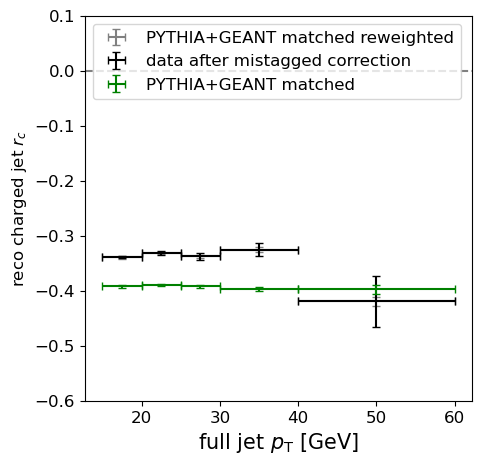

In [67]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pts_array_rw, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_match_bs_vs_pts_array_rw, capsize=3, color='grey', ls='none', label='PYTHIA+GEANT matched reweighted')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc1_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc1_err_array, capsize=3, color='k', ls='none', label='data after mistagged correction')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pts_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_match_bs_vs_pts_array, capsize=3, color='g', ls='none', label='PYTHIA+GEANT matched')
plt.xlabel('full jet $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('reco charged jet $r_c$')
plt.ylim(-0.6,0.1)
plt.legend(loc='upper left')

In [63]:
print(rc_match_bs_vs_pts_array_rw)

[-0.3389978087990394, -0.3314202738463346, -0.3376525007257003, -0.3253684271399414, -0.4192668533074789]


Text(20, -0.25, 'STAR data\n$p$+$p$ $\\sqrt{s}=200$ GeV\nanti-$k_{\\mathrm{T}}$ jets, $R=0.4$')

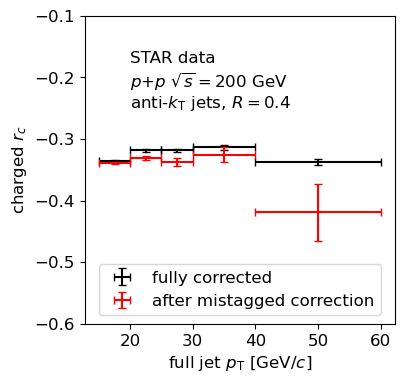

In [64]:
fig=plt.figure(figsize=(4,4))
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pt_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_match_bs_vs_pt_array, capsize=3, color='k', ls='none', label='fully corrected')
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc1_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc1_err_array, capsize=3, color='r', ls='none', label='after mistagged correction')
plt.xlabel('full jet $p_{\mathrm{T}}$ [GeV$/c$]')
plt.ylabel('charged $r_c$')
plt.ylim(-0.6,-0.1)
plt.legend(loc='lower center')
plt.text(20, -0.25, 'STAR data\n$p$+$p$ $\sqrt{s}=200$ GeV\nanti-$k_{\mathrm{T}}$ jets, $R=0.4$')

Plot result

(-0.6, 0.1)

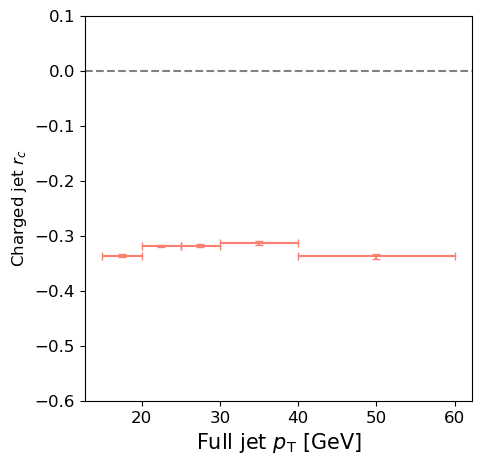

In [65]:
fig=plt.figure(figsize=(5,5))
plt.errorbar([17.5, 22.5, 27.5, 35, 50], rc_match_bs_vs_pt_array, xerr=[2.5, 2.5, 2.5, 5, 10], yerr=rc_err_match_bs_vs_pt_array, capsize=3, color='salmon', ls='none', label='sample 1 corrected')
#plt.errorbar([22.5, 27.5, 35], rc_match_bs_vs_pts_array[1:], xerr=[2.5, 2.5, 5], yerr=rc_err_match_bs_vs_pts_array[1:], capsize=3, color='r', ls='none', label='sample 1 corrected')
plt.xlabel('Full jet $p_{\mathrm{T}}$ [GeV]', fontsize=15)
plt.axhline(y=0.0, color='grey', linestyle='--')
plt.ylabel('Charged jet $r_c$')
plt.ylim(-0.6,0.1)
#plt.legend(loc='upper left', fontsize=15)

In [66]:
rc_match_bs_vs_pt_array

[-0.3363383503313372,
 -0.31858421634077183,
 -0.31837883403935086,
 -0.3137246070368501,
 -0.337476670722872]

In [93]:
rc_err_match_bs_vs_pt_array

[0.002902329760794436,
 0.0022562811409388753,
 0.0027941445346627894,
 0.003496919848053088,
 0.005194905950704135]